In [31]:
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Resolve path to outputs whether run from project root or notebooks/ directory
possible_paths = [
    Path('../outputs/sentiment_analyzed_comments.csv'),
    Path('outputs/sentiment_analyzed_comments.csv'),
    Path('sentiment_analyzed_comments.csv')
]
csv_path = next((p for p in possible_paths if p.exists()), Path('outputs/sentiment_analyzed_comments.csv'))

df = pd.read_csv(csv_path)

df['char_length'] = df['raw_comment'].astype(str).str.len()
df['word_count'] = df['raw_comment'].astype(str).str.split().str.len()

df[['source_portal', 'category', 'sentiment', 'sentiment_score', 'likes', 'word_count']].head(3)


,source_portal,category,sentiment,sentiment_score,likes,word_count
0,MyGov India,Policy Suggestion / Public Consultation,neutral,0,1,111
1,MyGov India,Policy Suggestion / Public Consultation,neutral,0,2,12
2,MyGov India,Policy Suggestion / Public Consultation,positive,1,2,17


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2012\1112947602.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="sentiment", palette="coolwarm")


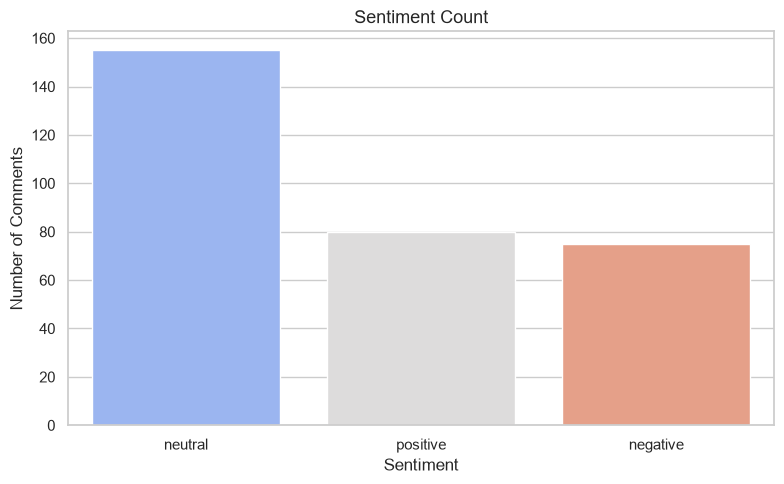

In [32]:
sns.countplot(data=df, x="sentiment", palette="coolwarm")
plt.title("Sentiment Count", fontsize=13)
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")

plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2012\2141391890.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="source_portal", palette="Blues_r", ax=axes[0])
C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2012\2141391890.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, y="category", palette="viridis", order=df["category"].value_counts().index, ax=axes[1])


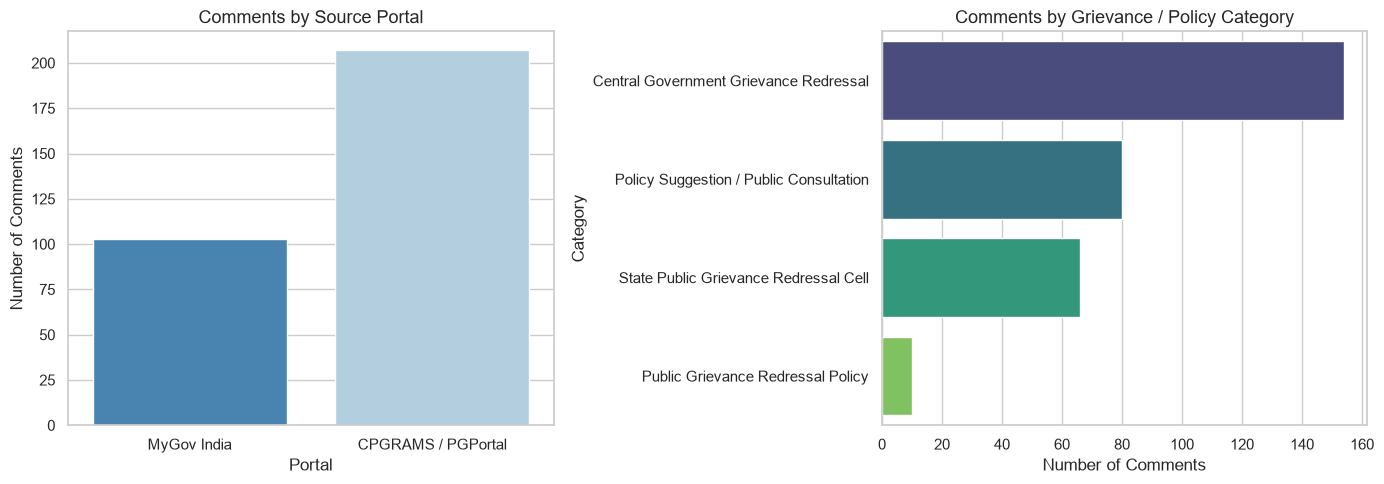

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=df, x="source_portal", palette="Blues_r", ax=axes[0])
axes[0].set_title("Comments by Source Portal", fontsize=13)
axes[0].set_xlabel("Portal")
axes[0].set_ylabel("Number of Comments")

sns.countplot(data=df, y="category", palette="viridis", order=df["category"].value_counts().index, ax=axes[1])
axes[1].set_title("Comments by Grievance / Policy Category", fontsize=13)
axes[1].set_xlabel("Number of Comments")
axes[1].set_ylabel("Category")

plt.tight_layout()
plt.show()

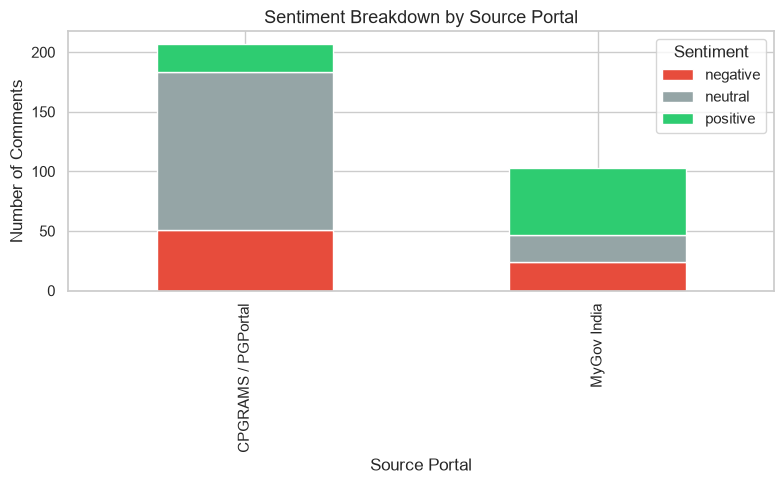

In [34]:
portal_sentiment = pd.crosstab(df["source_portal"], df["sentiment"])

portal_sentiment.plot(kind="bar", stacked=True, color=["#e74c3c", "#95a5a6", "#2ecc71"], figsize=(8, 5))
plt.title("Sentiment Breakdown by Source Portal", fontsize=13)
plt.xlabel("Source Portal")
plt.ylabel("Number of Comments")
plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

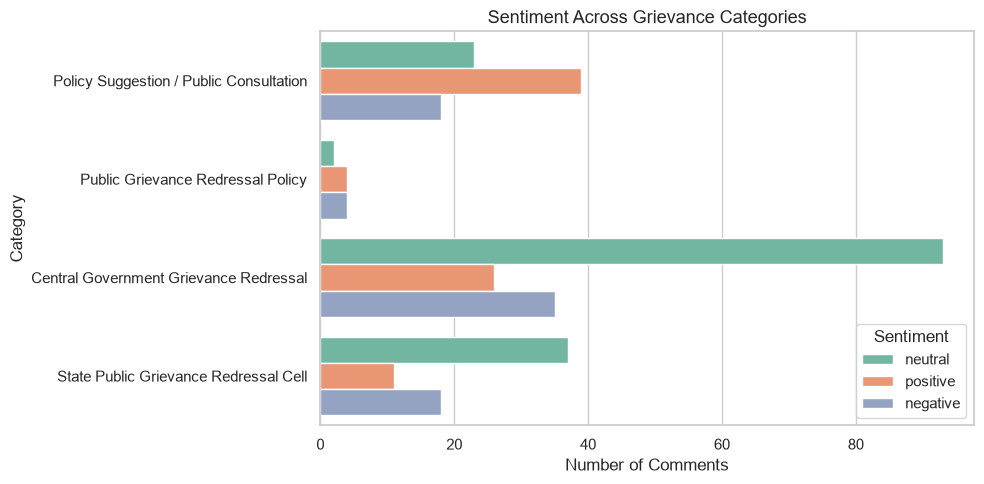

In [35]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, y="category", hue="sentiment", palette="Set2")
plt.title("Sentiment Across Grievance Categories", fontsize=13)
plt.xlabel("Number of Comments")
plt.ylabel("Category")
plt.legend(title="Sentiment", loc="lower right")
plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2012\4220133020.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="sentiment", y="likes", palette="mako", errorbar=None)


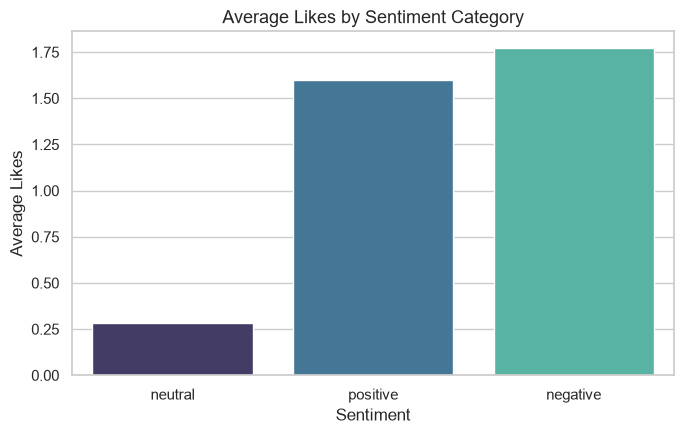

In [36]:
plt.figure(figsize=(7, 4.5))
sns.barplot(data=df, x="sentiment", y="likes", palette="mako", errorbar=None)
plt.title("Average Likes by Sentiment Category", fontsize=13)
plt.xlabel("Sentiment")
plt.ylabel("Average Likes")
plt.tight_layout()
plt.show()

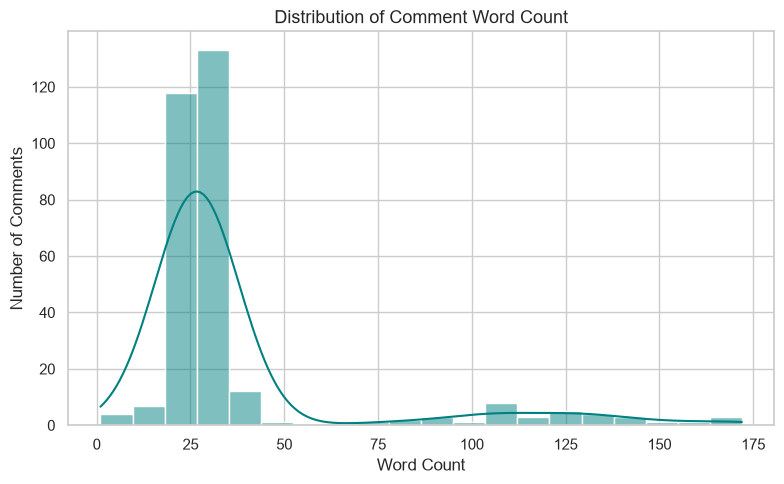

In [39]:
sns.histplot(df["word_count"], bins=20, kde=True, color="teal")
plt.title("Distribution of Comment Word Count", fontsize=13)
plt.xlabel("Word Count")
plt.ylabel("Number of Comments")


plt.tight_layout()
plt.show()

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_2012\1819668223.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_districts.values, y=top_districts.index, palette="crest")


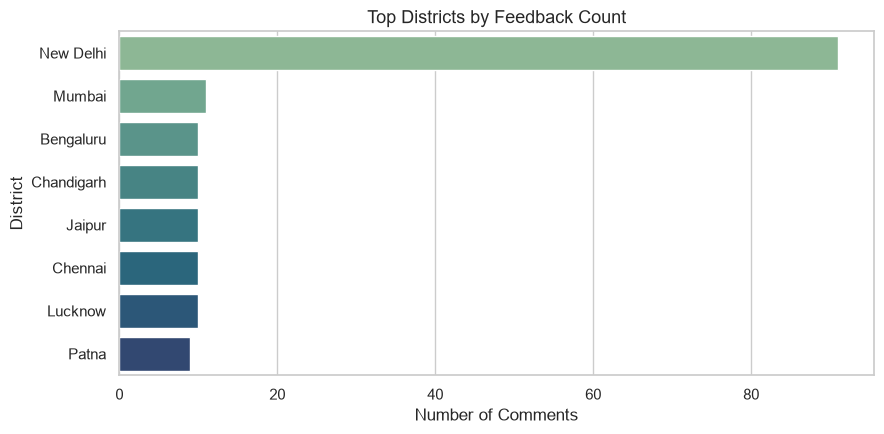

In [38]:
top_districts = df[df["district"] != "Not Specified"]["district"].value_counts().head(8)

plt.figure(figsize=(9, 4.5))
sns.barplot(x=top_districts.values, y=top_districts.index, palette="crest")
plt.title("Top Districts by Feedback Count", fontsize=13)
plt.xlabel("Number of Comments")
plt.ylabel("District")
plt.tight_layout()
plt.show()